# Nighttime Pothole Detection: YOLO11m, synthetic night to real night

**Pipeline**

| Step | What happens |
|---|---|
| 0 | Config and helpers |
| 1 | EDA of the **synthetic** night pothole set (train/val/test) and of the **real** night set |
| 2 | Inspect the real set's classes, keep **pothole only**, remap to class 0, and compare it with the synthetic set (brightness, box size) |
| 3 | Fine-tune **YOLO11m** (COCO-pretrained) on the synthetic set |
| 4 | Evaluate on the synthetic val/test splits (in-domain) |
| 5 | Run inference on the **real** night set with (a) the original COCO-pretrained YOLO11m and (b) the synthetic-fine-tuned YOLO11m |
| 6 | Comparison table, size-wise recall, qualitative figures, saved artifacts |

**Notes**
* The real set is used **only for inference/evaluation**, never for training or threshold tuning.
* The original COCO YOLO11m has **no pothole class**, so it is evaluated *class-agnostically*: any object it detects counts as a candidate pothole. This is the most generous possible reading, and it still shows how much fine-tuning matters.
* Set `SMOKE_TEST = True` in the config cell for a fast dry run (about 2 epochs on 5% of the data, 60 eval images) before the full run.

=== Running EDA on: /kaggle/input/datasets/phoenixz14/pothole-only ===

--- SPLIT: TRAIN ---
Total Images         : 1876
Total Label Files    : 1876
Unlabeled Images     : 0
Orphan Labels        : 0
Empty Labels (0 obj) : 0
Corrupt Images       : 0
Classes Found        : {0: 5149}
Annotation Formats   : {'bbox (5 values: cls xc yc w h)': 5149}
Out-of-bound Coords  : 0
Top 3 Image Sizes    : [((640, 640), 1876)]
Potholes per Image   : Mean=2.74, Median=2.0, Max=22
Box Area (% of img)  : Min=0.004%, Median=0.31%, Max=85.19%


--- SPLIT: VALID ---
Total Images         : 533
Total Label Files    : 533
Unlabeled Images     : 0
Orphan Labels        : 0
Empty Labels (0 obj) : 0
Corrupt Images       : 0
Classes Found        : {0: 1444}
Annotation Formats   : {'bbox (5 values: cls xc yc w h)': 1444}
Out-of-bound Coords  : 0
Top 3 Image Sizes    : [((640, 640), 533)]
Potholes per Image   : Mean=2.71, Median=2.0, Max=19
Box Area (% of img)  : Min=0.007%, Median=0.26%, Max=94.38%


--- SPLIT: TEST

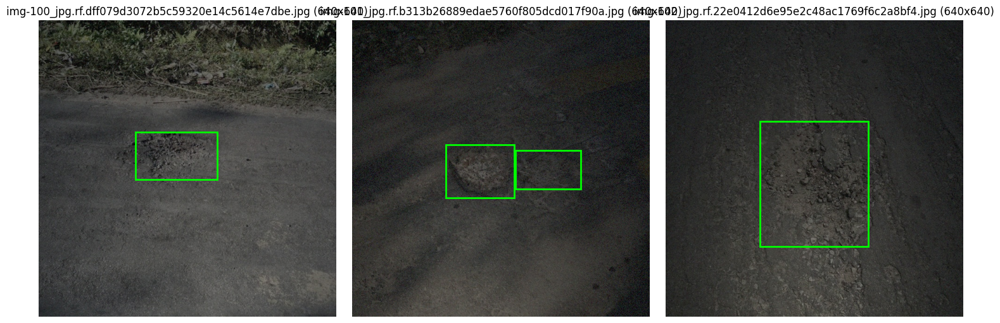

In [2]:
import os
from pathlib import Path
from collections import Counter
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# ==========================================
# SET YOUR DATASET ROOT DIRECTORY HERE
# ==========================================
DATASET_DIR = Path("/kaggle/input/datasets/phoenixz14/pothole-only")  # Should contain train, valid, test
SPLITS = ["train", "valid", "test"]
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def run_eda(root_dir):
    print(f"=== Running EDA on: {root_dir.resolve()} ===\n")
    
    for split in SPLITS:
        split_dir = root_dir / split
        if not split_dir.exists():
            print(f"[WARNING] Split folder not found: {split_dir}")
            continue
            
        img_dir = split_dir / "images"
        lbl_dir = split_dir / "labels"
        
        if not img_dir.exists() or not lbl_dir.exists():
            print(f"[WARNING] 'images' or 'labels' missing in {split}")
            continue

        img_files = {p.stem: p for p in img_dir.iterdir() if p.suffix.lower() in IMAGE_EXTS}
        lbl_files = {p.stem: p for p in lbl_dir.iterdir() if p.suffix.lower() == ".txt"}
        
        matched_stems = set(img_files.keys()) & set(lbl_files.keys())
        imgs_without_lbls = set(img_files.keys()) - set(lbl_files.keys())
        lbls_without_imgs = set(lbl_files.keys()) - set(img_files.keys())
        
        # Stats trackers
        empty_labels = 0
        corrupt_images = 0
        img_sizes = Counter()
        classes_found = Counter()
        format_types = Counter()  # 'bbox' (5 vals), 'polygon' (>5 vals), 'invalid' (<5 vals)
        boxes_per_img = []
        box_areas = []  # Normalized area (w * h)
        out_of_bounds = 0

        for stem in matched_stems:
            # 1. Check Image
            img_path = img_files[stem]
            try:
                with Image.open(img_path) as img:
                    img_sizes[img.size] += 1  # (width, height)
            except Exception:
                corrupt_images += 1
                continue

            # 2. Check Label
            lbl_path = lbl_files[stem]
            with open(lbl_path, "r") as f:
                lines = [line.strip() for line in f.readlines() if line.strip()]
                
            if len(lines) == 0:
                empty_labels += 1
                boxes_per_img.append(0)
                continue
                
            boxes_per_img.append(len(lines))
            
            for line in lines:
                parts = line.split()
                cls_id = int(float(parts[0]))
                coords = [float(x) for x in parts[1:]]
                classes_found[cls_id] += 1
                
                # Check coordinate bounds [0, 1]
                if any(c < 0.0 or c > 1.0 for c in coords):
                    out_of_bounds += 1
                
                # Check annotation type
                if len(parts) == 5:
                    format_types["bbox (5 values: cls xc yc w h)"] += 1
                    _, _, w, h = coords
                    box_areas.append(w * h)
                elif len(parts) > 5 and len(parts) % 2 == 1:
                    format_types["polygon (>5 values: cls x1 y1 x2 y2...)"] += 1
                    xs = coords[0::2]
                    ys = coords[1::2]
                    w = max(xs) - min(xs)
                    h = max(ys) - min(ys)
                    box_areas.append(w * h)
                else:
                    format_types[f"invalid ({len(parts)} values)"] += 1

        # Print Split Report
        print(f"--- SPLIT: {split.upper()} ---")
        print(f"Total Images         : {len(img_files)}")
        print(f"Total Label Files    : {len(lbl_files)}")
        print(f"Unlabeled Images     : {len(imgs_without_lbls)}")
        print(f"Orphan Labels        : {len(lbls_without_imgs)}")
        print(f"Empty Labels (0 obj) : {empty_labels}")
        print(f"Corrupt Images       : {corrupt_images}")
        print(f"Classes Found        : {dict(classes_found)}")
        print(f"Annotation Formats   : {dict(format_types)}")
        print(f"Out-of-bound Coords  : {out_of_bounds}")
        print(f"Top 3 Image Sizes    : {img_sizes.most_common(3)}")
        
        if boxes_per_img:
            print(f"Potholes per Image   : Mean={np.mean(boxes_per_img):.2f}, "
                  f"Median={np.median(boxes_per_img):.1f}, Max={np.max(boxes_per_img)}")
        if box_areas:
            areas = np.array(box_areas) * 100  # As percentage of image area
            print(f"Box Area (% of img)  : Min={areas.min():.3f}%, "
                  f"Median={np.median(areas):.2f}%, Max={areas.max():.2f}%")
        print("\n")


def visualize_samples(root_dir, split="train", num_samples=3):
    img_dir = root_dir / split / "images"
    lbl_dir = root_dir / split / "labels"
    if not img_dir.exists():
        return
        
    img_Paths = [p for p in img_dir.iterdir() if p.suffix.lower() in IMAGE_EXTS][:num_samples]
    if not img_Paths:
        return

    fig, axes = plt.subplots(1, len(img_Paths), figsize=(5 * len(img_Paths), 5))
    if len(img_Paths) == 1:
        axes = [axes]

    for ax, img_path in zip(axes, img_Paths):
        img = Image.open(img_path).convert("RGB")
        W, H = img.size
        ax.imshow(img)
        ax.set_title(f"{img_path.name} ({W}x{H})")
        ax.axis("off")

        lbl_path = lbl_dir / f"{img_path.stem}.txt"
        if lbl_path.exists():
            with open(lbl_path, "r") as f:
                for line in f:
                    parts = [float(x) for x in line.strip().split()]
                    if len(parts) == 5:
                        # Standard YOLO BBox
                        _, xc, yc, bw, bh = parts
                        x1 = (xc - bw / 2) * W
                        y1 = (yc - bh / 2) * H
                        rect = patches.Rectangle((x1, y1), bw * W, bh * H,
                                                 linewidth=2, edgecolor="lime", facecolor="none")
                        ax.add_patch(rect)
                    elif len(parts) > 5:
                        # Polygon Mask -> Draw both Polygon (cyan) and enclosing BBox (lime)
                        coords = parts[1:]
                        xs = [x * W for x in coords[0::2]]
                        ys = [y * H for y in coords[1::2]]
                        poly = patches.Polygon(list(zip(xs, ys)), closed=True,
                                               linewidth=1.5, edgecolor="cyan", facecolor="cyan", alpha=0.3)
                        ax.add_patch(poly)
                        # Enclosing Bounding Box
                        x1, y1, x2, y2 = min(xs), min(ys), max(xs), max(ys)
                        rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                                 linewidth=2, edgecolor="lime", linestyle="--", facecolor="none")
                        ax.add_patch(rect)

    plt.tight_layout()
    plt.savefig("eda_samples.png", dpi=150)
    print("Saved sample visualizations to 'eda_samples.png'")

if __name__ == "__main__":
    run_eda(DATASET_DIR)
    visualize_samples(DATASET_DIR, split="train", num_samples=3)

=== Running EDA on: /kaggle/input/datasets/tavishisharma09/night-potholes-yolov8-format ===

--- SPLIT: TRAIN ---
Total Images         : 1445
Total Label Files    : 1445
Unlabeled Images     : 0
Orphan Labels        : 0
Empty Labels (0 obj) : 0
Corrupt Images       : 0
Classes Found        : {1: 3055, 0: 330}
Annotation Formats   : {'bbox (5 values: cls xc yc w h)': 3385}
Out-of-bound Coords  : 0
Top 3 Image Sizes    : [((640, 640), 1445)]
Potholes per Image   : Mean=2.34, Median=2.0, Max=20
Box Area (% of img)  : Min=0.057%, Median=4.42%, Max=82.51%


[WARNING] Split folder not found: /kaggle/input/datasets/tavishisharma09/night-potholes-yolov8-format/valid
[WARNING] Split folder not found: /kaggle/input/datasets/tavishisharma09/night-potholes-yolov8-format/test
Saved sample visualizations to 'eda_samples.png'


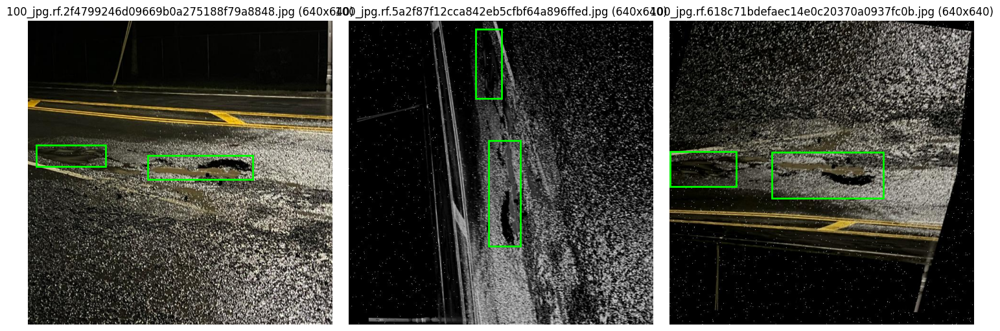

In [3]:
import os
from pathlib import Path
from collections import Counter
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# ==========================================
# SET YOUR DATASET ROOT DIRECTORY HERE
# ==========================================
DATASET_DIR = Path("/kaggle/input/datasets/tavishisharma09/night-potholes-yolov8-format")  # Should contain train, valid, test
SPLITS = ["train", "valid", "test"]
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def run_eda(root_dir):
    print(f"=== Running EDA on: {root_dir.resolve()} ===\n")
    
    for split in SPLITS:
        split_dir = root_dir / split
        if not split_dir.exists():
            print(f"[WARNING] Split folder not found: {split_dir}")
            continue
            
        img_dir = split_dir / "images"
        lbl_dir = split_dir / "labels"
        
        if not img_dir.exists() or not lbl_dir.exists():
            print(f"[WARNING] 'images' or 'labels' missing in {split}")
            continue

        img_files = {p.stem: p for p in img_dir.iterdir() if p.suffix.lower() in IMAGE_EXTS}
        lbl_files = {p.stem: p for p in lbl_dir.iterdir() if p.suffix.lower() == ".txt"}
        
        matched_stems = set(img_files.keys()) & set(lbl_files.keys())
        imgs_without_lbls = set(img_files.keys()) - set(lbl_files.keys())
        lbls_without_imgs = set(lbl_files.keys()) - set(img_files.keys())
        
        # Stats trackers
        empty_labels = 0
        corrupt_images = 0
        img_sizes = Counter()
        classes_found = Counter()
        format_types = Counter()  # 'bbox' (5 vals), 'polygon' (>5 vals), 'invalid' (<5 vals)
        boxes_per_img = []
        box_areas = []  # Normalized area (w * h)
        out_of_bounds = 0

        for stem in matched_stems:
            # 1. Check Image
            img_path = img_files[stem]
            try:
                with Image.open(img_path) as img:
                    img_sizes[img.size] += 1  # (width, height)
            except Exception:
                corrupt_images += 1
                continue

            # 2. Check Label
            lbl_path = lbl_files[stem]
            with open(lbl_path, "r") as f:
                lines = [line.strip() for line in f.readlines() if line.strip()]
                
            if len(lines) == 0:
                empty_labels += 1
                boxes_per_img.append(0)
                continue
                
            boxes_per_img.append(len(lines))
            
            for line in lines:
                parts = line.split()
                cls_id = int(float(parts[0]))
                coords = [float(x) for x in parts[1:]]
                classes_found[cls_id] += 1
                
                # Check coordinate bounds [0, 1]
                if any(c < 0.0 or c > 1.0 for c in coords):
                    out_of_bounds += 1
                
                # Check annotation type
                if len(parts) == 5:
                    format_types["bbox (5 values: cls xc yc w h)"] += 1
                    _, _, w, h = coords
                    box_areas.append(w * h)
                elif len(parts) > 5 and len(parts) % 2 == 1:
                    format_types["polygon (>5 values: cls x1 y1 x2 y2...)"] += 1
                    xs = coords[0::2]
                    ys = coords[1::2]
                    w = max(xs) - min(xs)
                    h = max(ys) - min(ys)
                    box_areas.append(w * h)
                else:
                    format_types[f"invalid ({len(parts)} values)"] += 1

        # Print Split Report
        print(f"--- SPLIT: {split.upper()} ---")
        print(f"Total Images         : {len(img_files)}")
        print(f"Total Label Files    : {len(lbl_files)}")
        print(f"Unlabeled Images     : {len(imgs_without_lbls)}")
        print(f"Orphan Labels        : {len(lbls_without_imgs)}")
        print(f"Empty Labels (0 obj) : {empty_labels}")
        print(f"Corrupt Images       : {corrupt_images}")
        print(f"Classes Found        : {dict(classes_found)}")
        print(f"Annotation Formats   : {dict(format_types)}")
        print(f"Out-of-bound Coords  : {out_of_bounds}")
        print(f"Top 3 Image Sizes    : {img_sizes.most_common(3)}")
        
        if boxes_per_img:
            print(f"Potholes per Image   : Mean={np.mean(boxes_per_img):.2f}, "
                  f"Median={np.median(boxes_per_img):.1f}, Max={np.max(boxes_per_img)}")
        if box_areas:
            areas = np.array(box_areas) * 100  # As percentage of image area
            print(f"Box Area (% of img)  : Min={areas.min():.3f}%, "
                  f"Median={np.median(areas):.2f}%, Max={areas.max():.2f}%")
        print("\n")


def visualize_samples(root_dir, split="train", num_samples=3):
    img_dir = root_dir / split / "images"
    lbl_dir = root_dir / split / "labels"
    if not img_dir.exists():
        return
        
    img_Paths = [p for p in img_dir.iterdir() if p.suffix.lower() in IMAGE_EXTS][:num_samples]
    if not img_Paths:
        return

    fig, axes = plt.subplots(1, len(img_Paths), figsize=(5 * len(img_Paths), 5))
    if len(img_Paths) == 1:
        axes = [axes]

    for ax, img_path in zip(axes, img_Paths):
        img = Image.open(img_path).convert("RGB")
        W, H = img.size
        ax.imshow(img)
        ax.set_title(f"{img_path.name} ({W}x{H})")
        ax.axis("off")

        lbl_path = lbl_dir / f"{img_path.stem}.txt"
        if lbl_path.exists():
            with open(lbl_path, "r") as f:
                for line in f:
                    parts = [float(x) for x in line.strip().split()]
                    if len(parts) == 5:
                        # Standard YOLO BBox
                        _, xc, yc, bw, bh = parts
                        x1 = (xc - bw / 2) * W
                        y1 = (yc - bh / 2) * H
                        rect = patches.Rectangle((x1, y1), bw * W, bh * H,
                                                 linewidth=2, edgecolor="lime", facecolor="none")
                        ax.add_patch(rect)
                    elif len(parts) > 5:
                        # Polygon Mask -> Draw both Polygon (cyan) and enclosing BBox (lime)
                        coords = parts[1:]
                        xs = [x * W for x in coords[0::2]]
                        ys = [y * H for y in coords[1::2]]
                        poly = patches.Polygon(list(zip(xs, ys)), closed=True,
                                               linewidth=1.5, edgecolor="cyan", facecolor="cyan", alpha=0.3)
                        ax.add_patch(poly)
                        # Enclosing Bounding Box
                        x1, y1, x2, y2 = min(xs), min(ys), max(xs), max(ys)
                        rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                                 linewidth=2, edgecolor="lime", linestyle="--", facecolor="none")
                        ax.add_patch(rect)

    plt.tight_layout()
    plt.savefig("eda_samples.png", dpi=150)
    print("Saved sample visualizations to 'eda_samples.png'")

if __name__ == "__main__":
    run_eda(DATASET_DIR)
    visualize_samples(DATASET_DIR, split="train", num_samples=3)

## 0. Setup

In [4]:
!pip install -q -U ultralytics

In [5]:
import os, sys, re, json, glob, shutil, random, time, yaml, warnings
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import cv2
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Image as IPyImage
from tqdm.auto import tqdm
from ultralytics import YOLO

warnings.filterwarnings("ignore")

# ============================ CONFIG ============================
SMOKE_TEST = False                     # True = quick dry run of the whole pipeline

SYNTH_DIR = Path("/kaggle/input/datasets/phoenixz14/pothole-only")                         # synthetic night set (train/valid/test)
REAL_DIR  = Path("/kaggle/input/datasets/tavishisharma09/night-potholes-yolov8-format")    # real night set
REAL_POTHOLE_CLASS_ID = 1          # None = auto-detect from data.yaml names. Set to 0 or 1 manually if auto-detect fails.

WORK = Path("/kaggle/working")
RUNS = WORK / "runs"
FIGS = WORK / "figures"
for d in (RUNS, FIGS):
    d.mkdir(parents=True, exist_ok=True)

MODEL_WEIGHTS = "yolo11m.pt"           # original COCO-pretrained YOLO11m
USE_CLAHE     = False                  # optional CLAHE on L-channel, applied identically to synthetic AND real images
IMGSZ         = 800                    # potholes are small in the synthetic set (median box about 0.3% of the image); 800 > 640 helps
BATCH         = 8                     
EPOCHS        = 100
PATIENCE      = 25
FRACTION      = 1.0                    # fraction of the training set used
MAX_EVAL_IMAGES = None                 # None = use all images when evaluating
RETRAIN       = False                  # False = reuse an existing best.pt in RUNS if present
EVAL_BATCH    = 16
SEED          = 42

if SMOKE_TEST:
    EPOCHS, IMGSZ, BATCH, FRACTION, MAX_EVAL_IMAGES, PATIENCE = 2, 640, 16, 0.05, 60, 5

TRAIN_NAME = "yolo11m_synthetic_ft" + ("_smoke" if SMOKE_TEST else "")
DEVICE = 0 if torch.cuda.is_available() else "cpu"

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("device:", DEVICE, "| torch", torch.__version__)

device: 0 | torch 2.11.0+cu128


In [6]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def find_dataset_root(base):
    """Return the folder that directly contains train/valid/test (searches up to 2 levels down)."""
    base = Path(base)
    if not base.exists():
        raise FileNotFoundError(f"{base} not found. Contents of /kaggle/input: {os.listdir('/kaggle/input') if Path('/kaggle/input').exists() else 'n/a'}")
    lvl1 = [p for p in base.iterdir() if p.is_dir()]
    lvl2 = [q for p in lvl1 for q in p.iterdir() if q.is_dir()]
    for c in [base] + lvl1 + lvl2:
        if any((c / s / "images").is_dir() for s in ("train", "valid", "val", "test")):
            return c
    raise FileNotFoundError(f"No YOLO-style split folders (<split>/images) found under {base}")

def split_dirs(root):
    """{'train'|'val'|'test': (images_dir, labels_dir)} for the splits that exist."""
    out = {}
    for key, names in {"train": ["train"], "val": ["valid", "val"], "test": ["test"]}.items():
        for n in names:
            if (root / n / "images").is_dir():
                out[key] = (root / n / "images", root / n / "labels")
                break
    return out

def list_images(d):
    return sorted(p for p in Path(d).iterdir() if p.suffix.lower() in IMAGE_EXTS)

def label_path_for(img_path):
    img_path = Path(img_path)
    return img_path.parent.parent / "labels" / f"{img_path.stem}.txt"

def read_yolo_labels(path):
    """Return array (n,5): cls, xc, yc, w, h (normalised). Polygons are converted to their enclosing box."""
    rows = []
    path = Path(path)
    if path.exists():
        for line in path.read_text().splitlines():
            p = line.split()
            if len(p) < 5:
                continue
            v = [float(x) for x in p]
            if len(v) == 5:
                c, xc, yc, w, h = v
            else:
                xs, ys = v[1::2], v[2::2]
                x1, x2, y1, y2 = min(xs), max(xs), min(ys), max(ys)
                c, xc, yc, w, h = v[0], (x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1
            rows.append([c, xc, yc, w, h])
    return np.array(rows, dtype=float).reshape(-1, 5)

_CLAHE = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
def save_image(src, dst, clahe=False):
    if not clahe:
        shutil.copy2(src, dst)
        return
    img = cv2.imread(str(src))
    l, a, b = cv2.split(cv2.cvtColor(img, cv2.COLOR_BGR2LAB))
    out = cv2.cvtColor(cv2.merge((_CLAHE.apply(l), a, b)), cv2.COLOR_LAB2BGR)
    cv2.imwrite(str(dst), out)

def subset(paths):
    paths = list(paths)
    if MAX_EVAL_IMAGES and len(paths) > MAX_EVAL_IMAGES:
        paths = random.Random(SEED).sample(paths, MAX_EVAL_IMAGES)
    return paths

def savefig(name):
    plt.savefig(FIGS / name, dpi=150, bbox_inches="tight")

## 1. Synthetic dataset: prepare the YOLO yaml

Training uses the synthetic night set exactly as in the EDA above. If `USE_CLAHE=True`, a CLAHE-enhanced copy is created and used for **both** synthetic and real data, so the model never sees a preprocessing mismatch.

In [7]:
synth_root = find_dataset_root(SYNTH_DIR)
synth = split_dirs(synth_root)
print("synthetic root:", synth_root, "| splits:", list(synth))

if USE_CLAHE:
    dst_root = WORK / "synthetic_clahe"
    if dst_root.exists():
        shutil.rmtree(dst_root)
    new = {}
    for sp, (idir, ldir) in synth.items():
        di, dl = dst_root / sp / "images", dst_root / sp / "labels"
        di.mkdir(parents=True); dl.mkdir(parents=True)
        for p in tqdm(list_images(idir), desc=f"CLAHE {sp}"):
            save_image(p, di / p.name, clahe=True)
            lp = label_path_for(p)
            if lp.exists():
                shutil.copy2(lp, dl / lp.name)
        new[sp] = (di, dl)
    synth = new

SYNTH_YAML = WORK / "synthetic_data.yaml"
with open(SYNTH_YAML, "w") as f:
    yaml.dump({"train": str(synth["train"][0]), "val": str(synth["val"][0]), "test": str(synth["test"][0]),
               "nc": 1, "names": {0: "pothole"}}, f, sort_keys=False)

synth_val_imgs  = subset(list_images(synth["val"][0]))
synth_test_imgs = subset(list_images(synth["test"][0]))
print({k: len(list_images(v[0])) for k, v in synth.items()}, "| eval subsets:", len(synth_val_imgs), len(synth_test_imgs))
print("yaml:", SYNTH_YAML)

synthetic root: /kaggle/input/datasets/phoenixz14/pothole-only | splits: ['train', 'val', 'test']
{'train': 1876, 'val': 533, 'test': 270} | eval subsets: 533 270
yaml: /kaggle/working/synthetic_data.yaml


## 2. Real night dataset: classes, pothole-only filtering, comparison with the synthetic set

The earlier EDA showed the real set has **two classes** (`{1: 3055, 0: 330}`) and only a `train` folder. The cell below prints the class names from `data.yaml` and shows examples per class so you can check which id is the pothole.

real root: /kaggle/input/datasets/tavishisharma09/night-potholes-yolov8-format | splits found: ['train']
data.yaml: names = {0: 'night-potholes', 1: 'pothole'}
boxes per class id: {0: 330, 1: 3055}


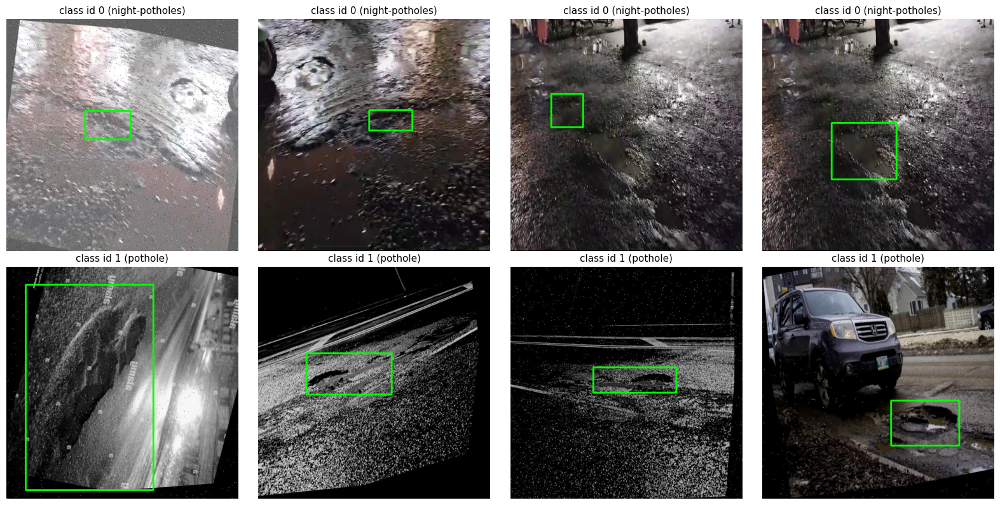

Using pothole class id(s): [1]


In [8]:
real_root = find_dataset_root(REAL_DIR)
real_splits = split_dirs(real_root)
print("real root:", real_root, "| splits found:", list(real_splits))

# --- class names from data.yaml (if any) ---
real_names = {}
for yp in list(real_root.glob("*.y*ml")) + list(Path(REAL_DIR).glob("*.y*ml")):
    d = yaml.safe_load(open(yp))
    if isinstance(d, dict) and "names" in d:
        n = d["names"]
        real_names = dict(enumerate(n)) if isinstance(n, list) else {int(k): v for k, v in n.items()}
        print(f"{yp.name}: names = {real_names}")
        break
else:
    print("[WARN] no data.yaml with names found. Decide the pothole id from the example images below.")

# --- per-class box counts over all splits ---
cls_counts = Counter()
per_class_examples = {}
for sp, (idir, ldir) in real_splits.items():
    for p in list_images(idir):
        lab = read_yolo_labels(label_path_for(p))
        for row in lab:
            c = int(row[0]); cls_counts[c] += 1
            per_class_examples.setdefault(c, [])
            if len(per_class_examples[c]) < 40:
                per_class_examples[c].append((p, row))
print("boxes per class id:", dict(sorted(cls_counts.items())))

# --- 4 example images per class, only that class's boxes drawn ---
ids = sorted(per_class_examples)
fig, axes = plt.subplots(len(ids), 4, figsize=(16, 4 * len(ids)), squeeze=False)
rng = random.Random(SEED)
for r_i, c in enumerate(ids):
    picks = rng.sample(per_class_examples[c], min(4, len(per_class_examples[c])))
    for a_i in range(4):
        ax = axes[r_i][a_i]; ax.axis("off")
        if a_i >= len(picks):
            continue
        p, row = picks[a_i]
        img = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB); H, W = img.shape[:2]
        _, xc, yc, w, h = row
        cv2.rectangle(img, (int((xc - w/2) * W), int((yc - h/2) * H)), (int((xc + w/2) * W), int((yc + h/2) * H)), (0, 255, 0), 3)
        ax.imshow(img)
        ax.set_title(f"class id {c} ({real_names.get(c, '?')})", fontsize=11)
plt.tight_layout(); savefig("real_class_examples.png"); plt.show()

# --- decide which id(s) are potholes ---
def pick_pothole_ids(names, override):
    if override is not None:
        return [int(override)]
    ids_ = [i for i, n in names.items() if "pothole" in re.sub(r"[^a-z]", "", str(n).lower())]
    if len(ids_) == 1:
        return ids_
    raise RuntimeError(
        f"Could not auto-detect the pothole class (names={names}). Look at real_class_examples.png above and set "
        f"REAL_POTHOLE_CLASS_ID in the config cell, then re-run from the config cell.")

REAL_POTHOLE_IDS = pick_pothole_ids(real_names, REAL_POTHOLE_CLASS_ID)
print("Using pothole class id(s):", REAL_POTHOLE_IDS)

In [9]:
# --- build the pothole-only, class-0 real set. Every image that has >=1 pothole is kept (same rule used for the synthetic set) ---
REAL_WORK = WORK / "real_night_pothole"
if REAL_WORK.exists():
    shutil.rmtree(REAL_WORK)
r_img, r_lbl = REAL_WORK / "test" / "images", REAL_WORK / "test" / "labels"
r_img.mkdir(parents=True); r_lbl.mkdir(parents=True)

kept_imgs = skipped_imgs = kept_boxes = dropped_boxes = 0
for sp, (idir, ldir) in real_splits.items():
    for p in tqdm(list_images(idir), desc=f"real/{sp}"):
        lab = read_yolo_labels(label_path_for(p))
        mask = np.isin(lab[:, 0].astype(int), REAL_POTHOLE_IDS)
        if mask.sum() == 0:
            skipped_imgs += 1; dropped_boxes += len(lab); continue
        name = f"{sp}__{p.name}"
        save_image(p, r_img / name, clahe=USE_CLAHE)
        with open(r_lbl / f"{Path(name).stem}.txt", "w") as f:
            for _, xc, yc, w, h in lab[mask]:
                f.write(f"0 {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}\n")
        kept_imgs += 1; kept_boxes += int(mask.sum()); dropped_boxes += int((~mask).sum())

print(f"kept images: {kept_imgs} | images without potholes skipped: {skipped_imgs} | pothole boxes: {kept_boxes} | non-pothole boxes dropped: {dropped_boxes}")
assert kept_imgs > 0, "No pothole images found. Check REAL_POTHOLE_CLASS_ID."

REAL_YAML = WORK / "real_night_data.yaml"
with open(REAL_YAML, "w") as f:
    yaml.dump({"train": str(r_img), "val": str(r_img), "test": str(r_img), "nc": 1, "names": {0: "pothole"}}, f, sort_keys=False)
real_imgs = subset(list_images(r_img))
print("real eval images:", len(real_imgs), "| yaml:", REAL_YAML)

real/train:   0%|          | 0/1445 [00:00<?, ?it/s]

kept images: 1330 | images without potholes skipped: 115 | pothole boxes: 3055 | non-pothole boxes dropped: 330
real eval images: 1330 | yaml: /kaggle/working/real_night_data.yaml


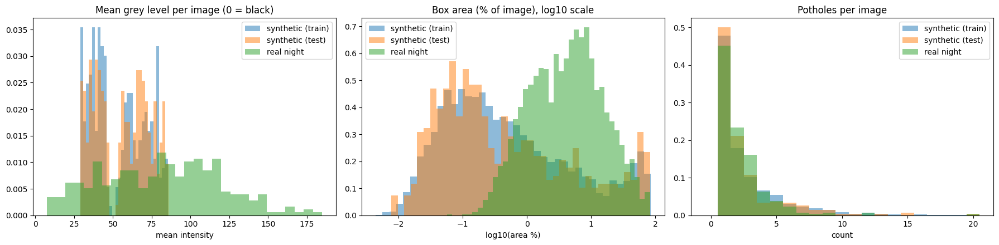

,images,boxes,mean brightness,median box area %,boxes/img
synthetic (train),1876.0,5149.0,53.54,0.31,2.74
synthetic (test),270.0,677.0,55.59,0.23,2.51
real night,1330.0,3055.0,81.29,4.29,2.30


In [10]:
# --- synthetic vs real: brightness, box size, boxes/image ---
def mean_brightness(paths, n=300):
    paths = random.Random(SEED).sample(list(paths), min(n, len(paths)))
    return np.array([cv2.imread(str(p), cv2.IMREAD_GRAYSCALE).mean() for p in paths])

def box_stats(paths):
    areas, per_img = [], []
    for p in paths:
        lab = read_yolo_labels(label_path_for(p))
        per_img.append(len(lab)); areas += list(lab[:, 3] * lab[:, 4] * 100)
    return np.array(areas), np.array(per_img)

sets = {"synthetic (train)": list_images(synth["train"][0]), "synthetic (test)": list(synth_test_imgs), "real night": list(real_imgs)}
bright = {k: mean_brightness(v) for k, v in sets.items()}
stats  = {k: box_stats(v) for k, v in sets.items()}

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for k in sets:
    ax[0].hist(bright[k], bins=30, alpha=0.5, density=True, label=k)
    ax[1].hist(np.log10(stats[k][0]), bins=40, alpha=0.5, density=True, label=k)
    ax[2].hist(stats[k][1], bins=np.arange(0, 22) - 0.5, alpha=0.5, density=True, label=k)
ax[0].set_title("Mean grey level per image (0 = black)"); ax[0].set_xlabel("mean intensity")
ax[1].set_title("Box area (% of image), log10 scale"); ax[1].set_xlabel("log10(area %)")
ax[2].set_title("Potholes per image"); ax[2].set_xlabel("count")
for a in ax: a.legend()
plt.tight_layout(); savefig("synthetic_vs_real_eda.png"); plt.show()

summary = pd.DataFrame({
    k: {"images": len(sets[k]), "boxes": len(stats[k][0]), "mean brightness": bright[k].mean(),
        "median box area %": np.median(stats[k][0]), "boxes/img": stats[k][1].mean()} for k in sets}).T.round(2)
display(summary)

## 3. Fine-tune YOLO11m on the synthetic night set

**Why this differs from the previous training cell.** The earlier run attached a CBAM block through an `on_train_start` callback. Ultralytics builds its EMA copy of the model *before* that callback fires, so the EMA weights (used for validation and saved as `best.pt`) do not contain the CBAM block, although the live model was trained with it. That mismatch is the likely reason validation mAP@0.5 started at about 0.08 and peaked at 0.54, below YOLOv8n/s (about 0.58). Here YOLO11m is fine-tuned **unmodified** from COCO weights with standard, well-tested settings, and a higher input resolution for the small potholes.

In [11]:
best_pt = RUNS / TRAIN_NAME / "weights" / "best.pt"

if best_pt.exists() and not RETRAIN:
    print(f"Found existing weights, skipping training: {best_pt}  (set RETRAIN=True to retrain)")
else:
    t0 = time.time()
    model = YOLO(MODEL_WEIGHTS)
    model.train(
        data=str(SYNTH_YAML),
        epochs=EPOCHS, patience=PATIENCE, imgsz=IMGSZ, batch=BATCH, fraction=FRACTION,
        optimizer="auto", cos_lr=True, close_mosaic=10, warmup_epochs=3,
        mosaic=1.0, mixup=0.1, scale=0.5, fliplr=0.5, flipud=0.0, degrees=0.0,
        hsv_h=0.015, hsv_s=0.6, hsv_v=0.4,
        seed=SEED, workers=2, device=DEVICE, plots=True,
        project=str(RUNS), name=TRAIN_NAME, exist_ok=True,
    )
    print(f"training time: {(time.time() - t0) / 60:.1f} min")

assert best_pt.exists(), f"best.pt not found at {best_pt}"
ft_model   = YOLO(str(best_pt))        # fine-tuned on synthetic night
coco_model = YOLO(MODEL_WEIGHTS)       # original pretrained, no pothole class
print("fine-tuned params:", sum(p.numel() for p in ft_model.model.parameters()) / 1e6, "M")

Ultralytics 8.4.191 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/synthetic_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.6, hsv_v=0.4, imgsz=800, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolo11m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11m_synthetic_ft, nbs=64, nms=None, opset=None, opt

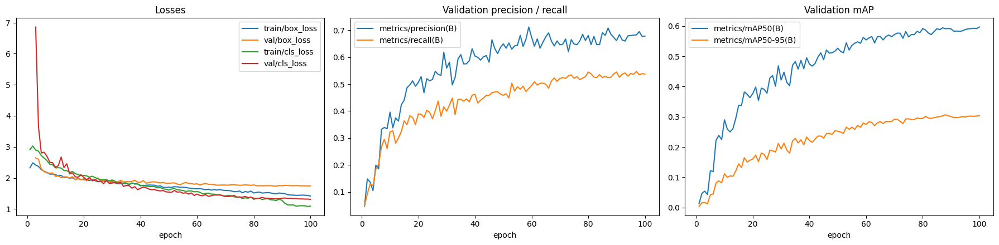

best epoch (by val mAP50): 100 | val mAP50 = 0.5967 | val mAP50-95 = 0.3034


In [12]:
# training curves
df = pd.read_csv(RUNS / TRAIN_NAME / "results.csv"); df.columns = [c.strip() for c in df.columns]
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for c in ("train/box_loss", "val/box_loss", "train/cls_loss", "val/cls_loss"):
    if c in df: ax[0].plot(df["epoch"], df[c], label=c)
ax[0].set_title("Losses"); ax[0].set_xlabel("epoch"); ax[0].legend()
for c in ("metrics/precision(B)", "metrics/recall(B)"):
    if c in df: ax[1].plot(df["epoch"], df[c], label=c)
ax[1].set_title("Validation precision / recall"); ax[1].set_xlabel("epoch"); ax[1].legend()
for c in ("metrics/mAP50(B)", "metrics/mAP50-95(B)"):
    if c in df: ax[2].plot(df["epoch"], df[c], label=c)
ax[2].set_title("Validation mAP"); ax[2].set_xlabel("epoch"); ax[2].legend()
plt.tight_layout(); savefig("training_curves.png"); plt.show()
bi = df["metrics/mAP50(B)"].idxmax()
print(f"best epoch (by val mAP50): {int(df.loc[bi, 'epoch'])} | val mAP50 = {df.loc[bi, 'metrics/mAP50(B)']:.4f} | val mAP50-95 = {df.loc[bi, 'metrics/mAP50-95(B)']:.4f}")

## 4. Evaluation tooling

Two complementary evaluations are used:

1. **Ultralytics `val()`**: the official numbers (P, R, mAP@0.5, mAP@0.5:0.95) for the fine-tuned model on the synthetic splits.
2. **A model-agnostic evaluator** (below): runs `predict()` and scores boxes itself (greedy IoU matching, 101-point AP, same as Ultralytics). It works for **any** model, including the COCO model, whose 80 classes do not fit a 1-class `val()`, and gives TP/FP/FN and recall by object size. It is cross-checked against `val()` where both apply.

In [13]:
IOU_THRS = np.linspace(0.5, 0.95, 10)
_trapz = np.trapezoid if hasattr(np, "trapezoid") else np.trapz

def iou_matrix(a, b):
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    ix1 = np.maximum(a[:, None, 0], b[None, :, 0]); iy1 = np.maximum(a[:, None, 1], b[None, :, 1])
    ix2 = np.minimum(a[:, None, 2], b[None, :, 2]); iy2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(ix2 - ix1, 0, None) * np.clip(iy2 - iy1, 0, None)
    aa = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]); ab = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (aa[:, None] + ab[None, :] - inter + 1e-9)

def gt_to_xyxy(lab, shape):
    h, w = shape
    xc, yc, bw, bh = lab[:, 1] * w, lab[:, 2] * h, lab[:, 3] * w, lab[:, 4] * h
    return np.stack([xc - bw / 2, yc - bh / 2, xc + bw / 2, yc + bh / 2], 1)

def predict_dataset(model, img_paths, conf=0.001, iou=0.7):
    out = []
    for i in tqdm(range(0, len(img_paths), EVAL_BATCH), desc="predict"):
        chunk = [str(p) for p in img_paths[i:i + EVAL_BATCH]]
        for r in model.predict(chunk, conf=conf, iou=iou, imgsz=IMGSZ, max_det=300, device=DEVICE, verbose=False):
            b = r.boxes
            out.append({"xyxy": b.xyxy.cpu().numpy(), "conf": b.conf.cpu().numpy(),
                        "cls": b.cls.cpu().numpy().astype(int), "shape": r.orig_shape})
    return out

def match_image(xyxy, conf, g, thr):
    """Greedy match by descending confidence. Returns sorted conf, tp flags, and for each GT the conf of its matching detection (-1 if missed)."""
    order = np.argsort(-conf)
    tp = np.zeros(len(order), bool); gt_conf = -np.ones(len(g))
    if len(order) and len(g):
        ious = iou_matrix(xyxy[order], g); taken = np.zeros(len(g), bool)
        for k in range(len(order)):
            cand = np.where(taken, -1.0, ious[k]); j = int(cand.argmax())
            if cand[j] >= thr:
                tp[k] = True; taken[j] = True; gt_conf[j] = conf[order[k]]
    return conf[order], tp, gt_conf

def average_precision(conf, tp, n_gt):
    if n_gt == 0 or len(conf) == 0:
        return 0.0
    o = np.argsort(-conf); tp = tp[o]
    ctp, cfp = np.cumsum(tp), np.cumsum(~tp)
    rec, prec = ctp / n_gt, ctp / (ctp + cfp)
    mrec = np.concatenate([[0.0], rec, [1.0]]); mpre = np.concatenate([[1.0], prec, [0.0]])
    mpre = np.flip(np.maximum.accumulate(np.flip(mpre)))
    x = np.linspace(0, 1, 101)
    return float(_trapz(np.interp(x, mrec, mpre), x))

def evaluate_predictions(preds, img_paths, name=""):
    gts = [gt_to_xyxy(read_yolo_labels(label_path_for(p)), pr["shape"]) for p, pr in zip(img_paths, preds)]
    n_gt = int(sum(len(g) for g in gts))
    gt_area = np.concatenate([((g[:, 2] - g[:, 0]) * (g[:, 3] - g[:, 1])) / (pr["shape"][0] * pr["shape"][1]) for g, pr in zip(gts, preds)])
    aps, res50 = [], None
    for thr in IOU_THRS:
        confs, tps, gtc = [], [], []
        for pr, g in zip(preds, gts):
            c, t, gc = match_image(pr["xyxy"], pr["conf"], g, thr)
            confs.append(c); tps.append(t); gtc.append(gc)
        confs, tps, gtc = np.concatenate(confs), np.concatenate(tps), np.concatenate(gtc)
        aps.append(average_precision(confs, tps, n_gt))
        if abs(thr - 0.5) < 1e-9:
            res50 = (confs, tps, gtc)
    return {"name": name, "n_images": len(img_paths), "n_gt": n_gt, "ap50": aps[0], "ap5095": float(np.mean(aps)),
            "conf50": res50[0], "tp50": res50[1], "gt_conf50": res50[2], "gt_area": gt_area}

def op_point(res, t):
    keep = res["conf50"] >= t
    tp = int(res["tp50"][keep].sum()); fp = int(keep.sum() - tp); fn = res["n_gt"] - tp
    p, r = tp / max(tp + fp, 1), tp / max(res["n_gt"], 1)
    return {"conf": float(t), "P": p, "R": r, "F1": 2 * p * r / max(p + r, 1e-9), "TP": tp, "FP": fp, "FN": fn}

def best_f1_conf(res):
    grid = np.linspace(0.01, 0.99, 99)
    return float(grid[int(np.argmax([op_point(res, t)["F1"] for t in grid]))])

SIZE_BINS = [("small (<1% of image)", 0, 0.01), ("medium (1-10%)", 0.01, 0.10), ("large (>=10%)", 0.10, 9)]
def recall_by_size(res, t):
    out = {}
    for lbl, lo, hi in SIZE_BINS:
        m = (res["gt_area"] >= lo) & (res["gt_area"] < hi)
        out[lbl] = (int(m.sum()), float((res["gt_conf50"][m] >= t).mean()) if m.sum() else float("nan"))
    return out

def full_eval(model, img_paths, name):
    preds = predict_dataset(model, img_paths)
    return evaluate_predictions(preds, img_paths, name), preds

def ultra_val(model, yaml_path, split, name):
    m = model.val(data=str(yaml_path), split=split, imgsz=IMGSZ, batch=EVAL_BATCH, conf=0.001, iou=0.7, device=DEVICE,
                  plots=True, project=str(RUNS / "eval"), name=name, exist_ok=True, verbose=False)
    p, r = float(m.box.mp), float(m.box.mr)
    return {"P": p, "R": r, "F1": 2 * p * r / max(p + r, 1e-9), "mAP50": float(m.box.map50), "mAP50-95": float(m.box.map)}

## 5. Synthetic night data: in-domain results (fine-tuned YOLO11m)

In [14]:
ultra_synth_val  = ultra_val(ft_model, SYNTH_YAML, "val",  "ft_synth_val")
ultra_synth_test = ultra_val(ft_model, SYNTH_YAML, "test", "ft_synth_test")
print(pd.DataFrame({"Validation": ultra_synth_val, "Test": ultra_synth_test}).T.round(4).to_string())

# operating point is chosen on the SYNTHETIC VALIDATION set only, then reused unchanged everywhere else
res_ft_synth_val,  _                 = full_eval(ft_model, synth_val_imgs,  "fine-tuned | synthetic val")
res_ft_synth_test, preds_ft_synth_test = full_eval(ft_model, synth_test_imgs, "fine-tuned | synthetic test")
CONF_REF = best_f1_conf(res_ft_synth_val)
print(f"\nreference confidence threshold (max-F1 on synthetic val): {CONF_REF:.2f}")
print("custom-evaluator cross-check  val : mAP50 = %.4f  mAP50-95 = %.4f   (ultralytics: %.4f / %.4f)" %
      (res_ft_synth_val["ap50"], res_ft_synth_val["ap5095"], ultra_synth_val["mAP50"], ultra_synth_val["mAP50-95"]))
print("custom-evaluator cross-check  test: mAP50 = %.4f  mAP50-95 = %.4f   (ultralytics: %.4f / %.4f)" %
      (res_ft_synth_test["ap50"], res_ft_synth_test["ap5095"], ultra_synth_test["mAP50"], ultra_synth_test["mAP50-95"]))
print("test @ CONF_REF:", {k: round(v, 4) if isinstance(v, float) else v for k, v in op_point(res_ft_synth_test, CONF_REF).items()})

Ultralytics 8.4.191 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11m summary (fused): 125 layers, 20,030,803 parameters, 0 gradients, 67.8 GFLOPs
val: Fast image access ✅ (ping: 0.2±0.1 ms, read: 364.7±87.8 MB/s, size: 184.1 KB)
val: Scanning /kaggle/input/datasets/phoenixz14/pothole-only/valid/labels... 533 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 533/533 848.6it/s 0.6s0.0s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/phoenixz14/pothole-only/valid is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 34/34 1.3it/s 26.4s0.8ss
                   all        533       1444      0.646      0.551      0.591      0.308
Speed: 2.0ms preprocess, 42.9ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to /kaggle/working/runs/eval/ft_synth_val
Ultralytics 8.4.191 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11m summary (fused):

predict:   0%|          | 0/34 [00:00<?, ?it/s]

predict:   0%|          | 0/17 [00:00<?, ?it/s]


reference confidence threshold (max-F1 on synthetic val): 0.30
custom-evaluator cross-check  val : mAP50 = 0.5708  mAP50-95 = 0.2904   (ultralytics: 0.5914 / 0.3076)
custom-evaluator cross-check  test: mAP50 = 0.5888  mAP50-95 = 0.2930   (ultralytics: 0.6072 / 0.3105)
test @ CONF_REF: {'conf': 0.3, 'P': 0.6679, 'R': 0.5288, 'F1': 0.5903, 'TP': 358, 'FP': 178, 'FN': 319}


BoxF1_curve.png


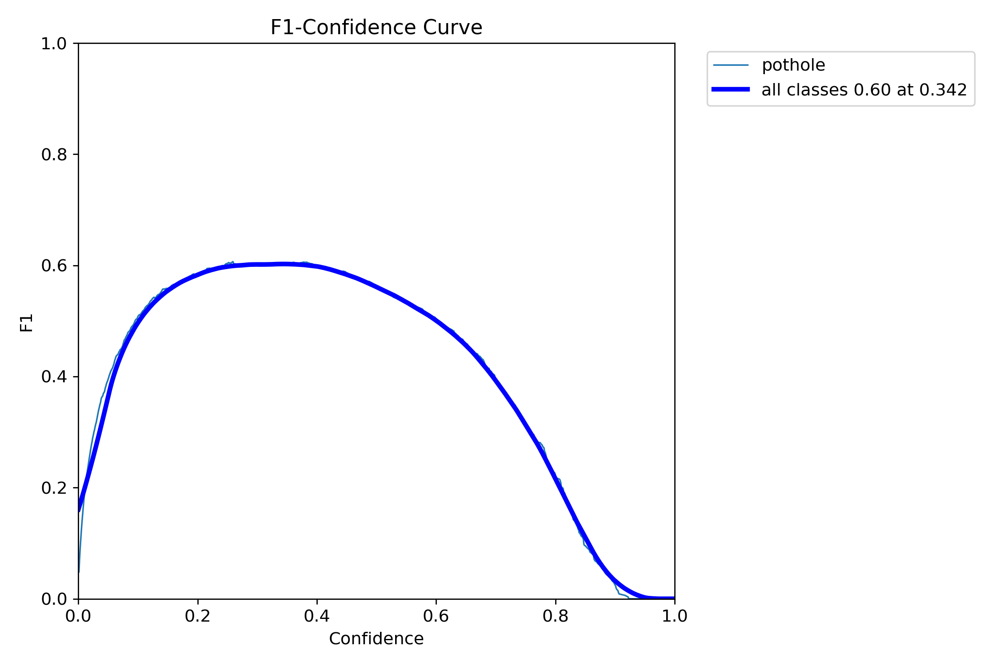

confusion_matrix_normalized.png


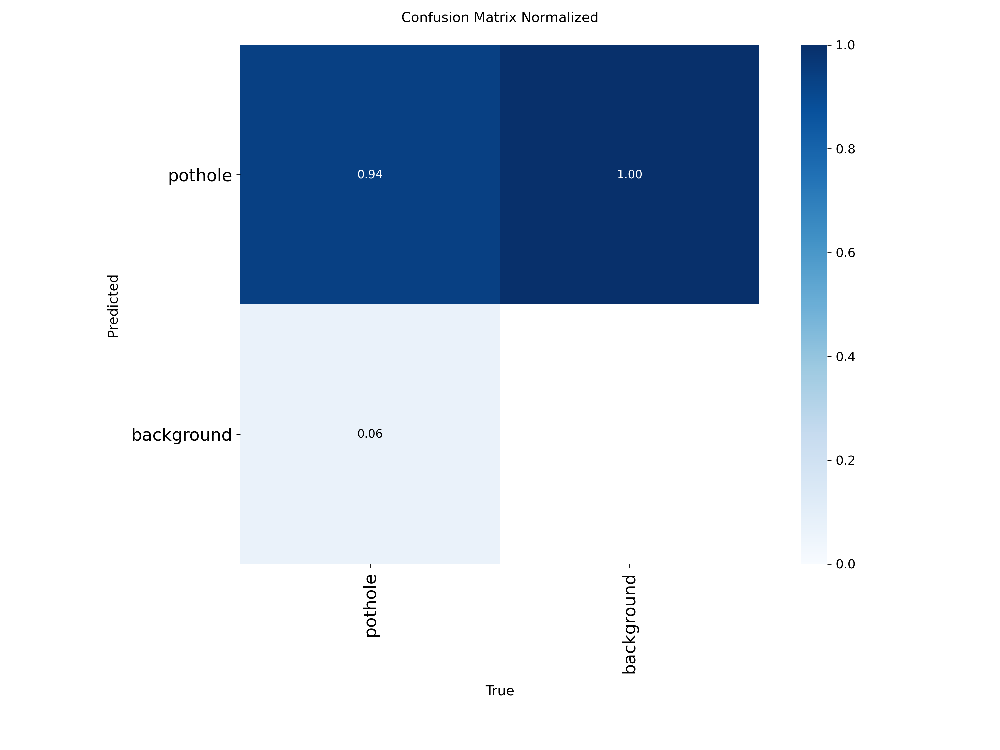

val_batch0_pred.jpg


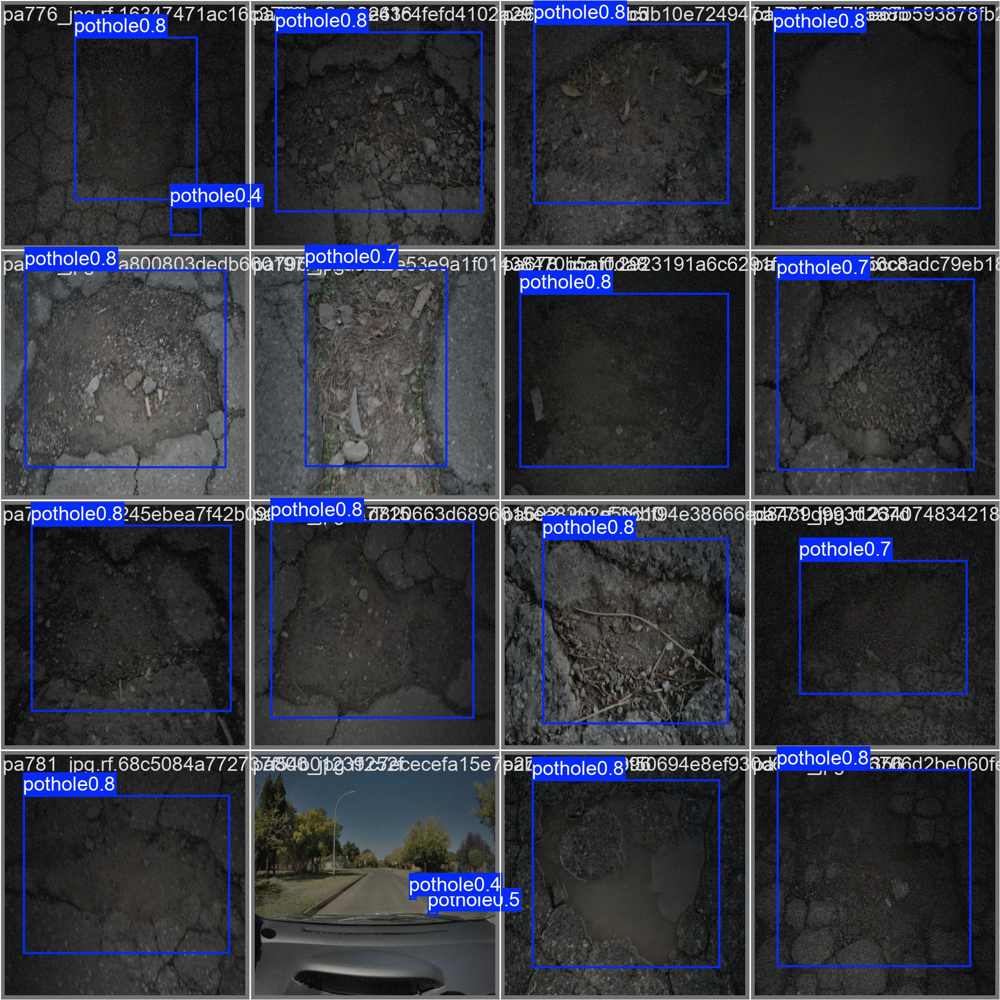

In [15]:
# Ultralytics' own diagnostic plots for the synthetic test split
for fn in ("PR_curve.png", "BoxF1_curve.png", "confusion_matrix_normalized.png", "val_batch0_pred.jpg"):
    p = RUNS / "eval" / "ft_synth_test" / fn
    if p.exists():
        print(fn); display(IPyImage(filename=str(p), width=700))

## 6. Inference on the real night dataset: original YOLO11m vs synthetic-fine-tuned YOLO11m

Both models are scored with the same evaluator, the same image size and the same NMS settings. The fine-tuned model runs at the confidence threshold chosen on the *synthetic validation set* (`CONF_REF`), so nothing is tuned on the real data. An "oracle" best-F1 threshold on the real set is also reported, only to show how much a threshold shift could recover.

In [20]:
import gc, sys

sys.last_traceback = sys.last_value = sys.last_type = None
for name in ("r", "i", "sample"):
    globals().pop(name, None)
coco_model.predictor = None          # drop the cached predictor (and its buffers); it is rebuilt on the next predict
gc.collect(); torch.cuda.empty_cache()
print(f"GPU memory in use: {torch.cuda.memory_allocated() / 1e9:.2f} GB allocated, {torch.cuda.memory_reserved() / 1e9:.2f} GB reserved")

# what does the COCO model actually fire on? (small chunks, plenty of headroom)
cnt = Counter()
sample = [str(p) for p in real_imgs[:200]]
for i in range(0, len(sample), 4):
    for r in coco_model.predict(sample[i:i + 4], conf=0.25, imgsz=IMGSZ, device=DEVICE, verbose=False):
        cnt.update(coco_model.names[int(c)] for c in r.boxes.cls)
print("COCO classes detected on real night images (first 200 images, conf>=0.25):", cnt.most_common(8) or "nothing")

# cross-check: Ultralytics val on the real set for the fine-tuned model
gc.collect(); torch.cuda.empty_cache()
ultra_real_ft = ultra_val(ft_model, REAL_YAML, "test", "ft_real")
print("fine-tuned on real | custom: mAP50 = %.4f / mAP50-95 = %.4f | ultralytics: %.4f / %.4f" %
      (res_ft_real["ap50"], res_ft_real["ap5095"], ultra_real_ft["mAP50"], ultra_real_ft["mAP50-95"]))

GPU memory in use: 0.77 GB allocated, 9.12 GB reserved
COCO classes detected on real night images (first 200 images, conf>=0.25): [('car', 69), ('person', 34), ('truck', 7), ('motorcycle', 5), ('knife', 4), ('train', 2), ('dog', 2), ('umbrella', 2)]
Ultralytics 8.4.191 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11m summary (fused): 125 layers, 20,030,803 parameters, 0 gradients, 67.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1604.7±543.3 MB/s, size: 55.9 KB)
val: Scanning /kaggle/working/real_night_pothole/test/labels... 1330 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1330/1330 1.2Kit/s 1.1s0.0s
val: New cache created: /kaggle/working/real_night_pothole/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 84/84 1.4it/s 1:020.7sss
                   all       1330       3055      0.305      0.234       0.19     0.0699
Speed: 1.6ms preprocess, 41.5ms inference, 0.0ms 

,Images,GT boxes,mAP@0.5,mAP@0.5:0.95,P@0.30,R@0.30,F1@0.30,TP,FP,FN,oracle conf,oracle F1
Model | Dataset,,,,,,,,,,,,
original COCO | synthetic test,270,677,0.0058,0.0028,0.0053,0.0015,0.0023,1,188,676,0.02,0.0290
fine-tuned | synthetic test,270,677,0.5888,0.2930,0.6679,0.5288,0.5903,358,178,319,0.26,0.5951
original COCO | real night,1330,3055,0.0129,0.0041,0.0532,0.0134,0.0214,41,729,3014,0.06,0.0584
fine-tuned (synthetic) | real night,1330,3055,0.1679,0.0650,0.2962,0.2046,0.2420,625,1485,2430,0.29,0.2440


recall@0.30                \
model                fine-tuned (synthetic) original COCO   
size                                                        
large (>=10%)                         0.298         0.031   
medium (1-10%)                        0.182         0.010   
small (<1% of image)                  0.141         0.000   

                                   GT boxes                
model                fine-tuned (synthetic) original COCO  
size                                                       
large (>=10%)                         782.0         782.0  
medium (1-10%)                       1763.0        1763.0  
small (<1% of image)                  510.0         510.0

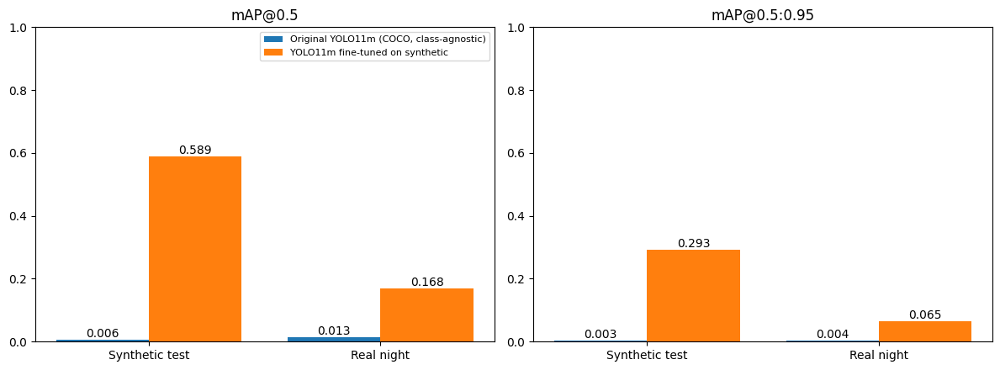

In [22]:
# ---- master comparison table ----
rows = []
for res in (res_coco_synth, res_ft_synth_test, res_coco_real, res_ft_real):
    ref, orc_t = op_point(res, CONF_REF), best_f1_conf(res)
    orc = op_point(res, orc_t)
    rows.append({
        "Model | Dataset": res["name"], "Images": res["n_images"], "GT boxes": res["n_gt"],
        "mAP@0.5": res["ap50"], "mAP@0.5:0.95": res["ap5095"],
        f"P@{CONF_REF:.2f}": ref["P"], f"R@{CONF_REF:.2f}": ref["R"], f"F1@{CONF_REF:.2f}": ref["F1"],
        "TP": ref["TP"], "FP": ref["FP"], "FN": ref["FN"],
        "oracle conf": orc_t, "oracle F1": orc["F1"]})
comp = pd.DataFrame(rows).set_index("Model | Dataset")
display(comp.round(4))

# ---- recall by object size on the real set ----
size_rows = []
for res in (res_coco_real, res_ft_real):
    for lbl, (n, rc) in recall_by_size(res, CONF_REF).items():
        size_rows.append({"model": res["name"].split(" | ")[0], "size": lbl, "GT boxes": n, f"recall@{CONF_REF:.2f}": rc})
size_df = pd.DataFrame(size_rows).pivot(index="size", columns="model", values=[f"recall@{CONF_REF:.2f}", "GT boxes"])
display(size_df.round(3))

# ---- bar chart ----
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
labels = ["Synthetic test", "Real night"]
for k, (metric, title) in enumerate((("ap50", "mAP@0.5"), ("ap5095", "mAP@0.5:0.95"))):
    coco_v = [res_coco_synth[metric], res_coco_real[metric]]; ft_v = [res_ft_synth_test[metric], res_ft_real[metric]]
    x = np.arange(2)
    b1 = ax[k].bar(x - 0.2, coco_v, 0.4, label="Original YOLO11m (COCO, class-agnostic)")
    b2 = ax[k].bar(x + 0.2, ft_v, 0.4, label="YOLO11m fine-tuned on synthetic")
    ax[k].bar_label(b1, fmt="%.3f"); ax[k].bar_label(b2, fmt="%.3f")
    ax[k].set_xticks(x); ax[k].set_xticklabels(labels); ax[k].set_title(title); ax[k].set_ylim(0, 1)
ax[0].legend(loc="upper right", fontsize=8)
plt.tight_layout(); savefig("model_comparison.png"); plt.show()

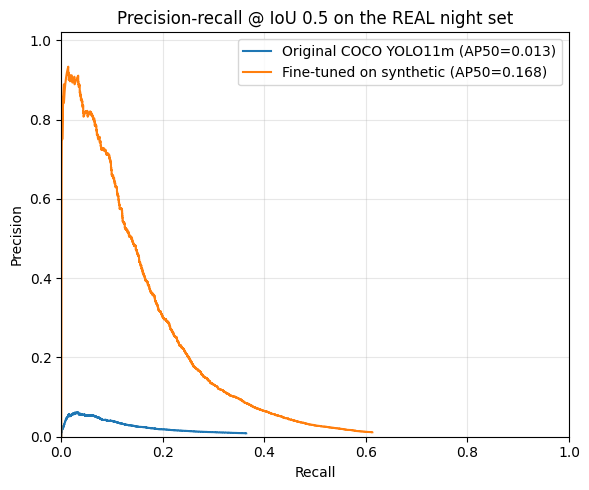

In [23]:
# ---- PR curves on the real set ----
def pr_curve(res):
    o = np.argsort(-res["conf50"]); tp = res["tp50"][o]
    ctp, cfp = np.cumsum(tp), np.cumsum(~tp)
    return ctp / max(res["n_gt"], 1), ctp / np.maximum(ctp + cfp, 1)

plt.figure(figsize=(6, 5))
for res, lab in ((res_coco_real, "Original COCO YOLO11m"), (res_ft_real, "Fine-tuned on synthetic")):
    r_, p_ = pr_curve(res); plt.plot(r_, p_, label=f"{lab} (AP50={res['ap50']:.3f})")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Precision-recall @ IoU 0.5 on the REAL night set")
plt.xlim(0, 1); plt.ylim(0, 1.02); plt.grid(alpha=.3); plt.legend()
plt.tight_layout(); savefig("pr_curve_real.png"); plt.show()

## 7. Qualitative results (real night images)

Green = ground truth. Middle column = raw **original COCO YOLO11m** output (conf ≥ 0.25, with its COCO class names). Right column = **fine-tuned** model at `CONF_REF`.

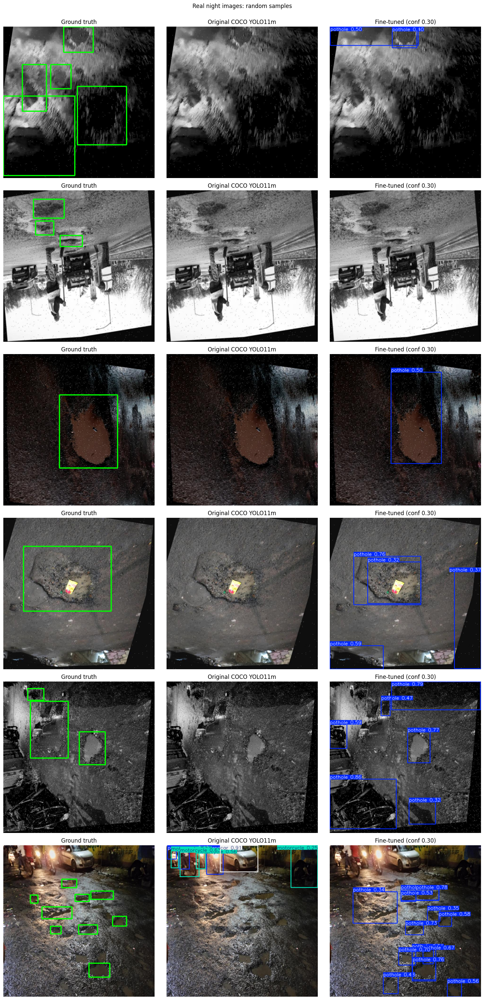

In [27]:
def draw_gt(img_bgr, lab):
    h, w = img_bgr.shape[:2]
    for _, xc, yc, bw, bh in lab:
        cv2.rectangle(img_bgr, (int((xc - bw/2) * w), int((yc - bh/2) * h)), (int((xc + bw/2) * w), int((yc + bh/2) * h)), (0, 255, 0), 3)
    return img_bgr

def show_grid(paths, fname, title):
    fig, axes = plt.subplots(len(paths), 3, figsize=(15, 5 * len(paths)), squeeze=False)
    for i, p in enumerate(paths):
        gt = draw_gt(cv2.imread(str(p)), read_yolo_labels(label_path_for(p)))
        c  = coco_model.predict(str(p), conf=0.25, imgsz=IMGSZ, device=DEVICE, verbose=False)[0].plot(line_width=2)
        f  = ft_model.predict(str(p), conf=CONF_REF, imgsz=IMGSZ, device=DEVICE, verbose=False)[0].plot(line_width=2)
        for j, (im, t) in enumerate(((gt, "Ground truth"), (c, "Original COCO YOLO11m"), (f, f"Fine-tuned (conf {CONF_REF:.2f})"))):
            axes[i][j].imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); axes[i][j].axis("off"); axes[i][j].set_title(t)
    plt.suptitle(title, y=1.0); plt.tight_layout(); savefig(fname); plt.show()

rng = random.Random(24)
show_grid(rng.sample(list(real_imgs), min(6, len(real_imgs))), "qualitative_real.png", "Real night images: random samples")

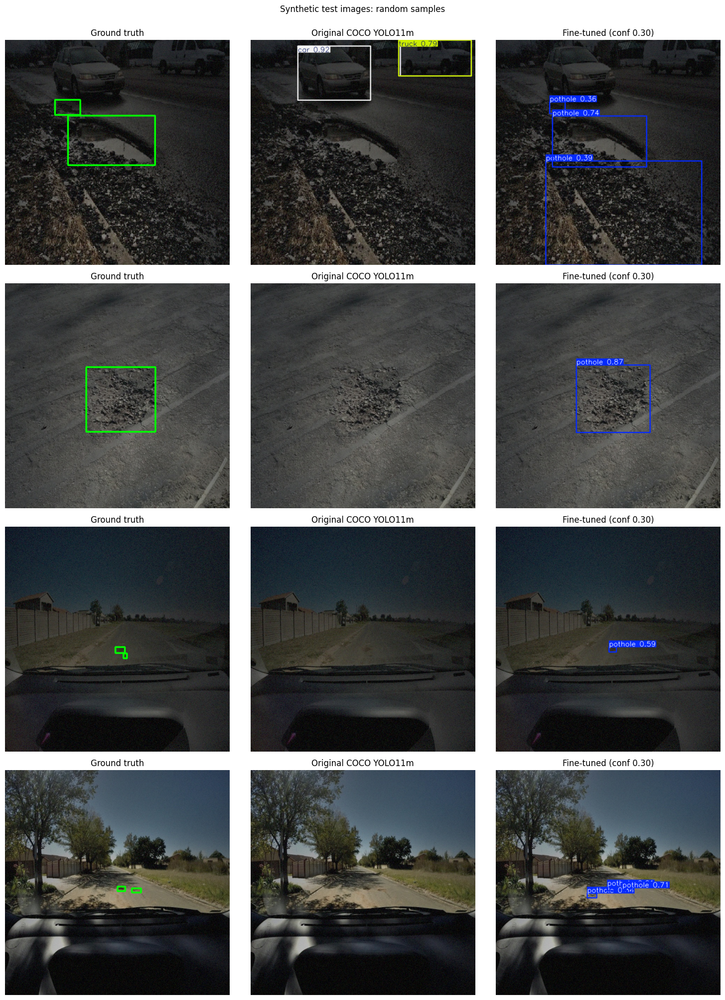

In [29]:
# synthetic test examples for reference
show_grid(random.Random(SEED).sample(list(synth_test_imgs), min(4, len(synth_test_imgs))), "qualitative_synth.png", "Synthetic test images: random samples")

## 8. Save everything for the report

In [30]:
comp.round(4).to_csv(WORK / "results_comparison.csv")
size_df.round(4).to_csv(WORK / "results_recall_by_size.csv")
summary_json = {
    "config": {"model": MODEL_WEIGHTS, "imgsz": IMGSZ, "epochs_configured": EPOCHS, "batch": BATCH, "use_clahe": USE_CLAHE,
               "smoke_test": SMOKE_TEST, "conf_ref_from_synth_val": CONF_REF, "pothole_class_ids_real": REAL_POTHOLE_IDS},
    "datasets": {"synthetic_val_images": len(synth_val_imgs), "synthetic_test_images": len(synth_test_imgs),
                 "real_images": len(real_imgs), "real_pothole_boxes": int(res_ft_real["n_gt"])},
    "ultralytics_val": {"synthetic_val": ultra_synth_val, "synthetic_test": ultra_synth_test, "real_finetuned": ultra_real_ft},
    "custom_eval": {r["name"]: {"mAP50": r["ap50"], "mAP50-95": r["ap5095"], **op_point(r, CONF_REF)}
                    for r in (res_coco_synth, res_ft_synth_val, res_ft_synth_test, res_coco_real, res_ft_real)},
}
(WORK / "results_summary.json").write_text(json.dumps(summary_json, indent=2))

archive = shutil.make_archive(str(WORK / "report_artifacts"), "zip", root_dir=WORK, base_dir="figures")
print("saved:", WORK / "results_comparison.csv", WORK / "results_recall_by_size.csv", WORK / "results_summary.json", archive, sep="\n  ")
print("best weights:", best_pt)
print(json.dumps(summary_json["custom_eval"], indent=2))

saved:
  /kaggle/working/results_comparison.csv
  /kaggle/working/results_recall_by_size.csv
  /kaggle/working/results_summary.json
  /kaggle/working/report_artifacts.zip
best weights: /kaggle/working/runs/yolo11m_synthetic_ft/weights/best.pt
{
  "original COCO | synthetic test": {
    "mAP50": 0.005789520152025811,
    "mAP50-95": 0.0028299392373122454,
    "conf": 0.3,
    "P": 0.005291005291005291,
    "R": 0.0014771048744460858,
    "F1": 0.0023094688221709007,
    "TP": 1,
    "FP": 188,
    "FN": 676
  },
  "fine-tuned | synthetic val": {
    "mAP50": 0.5707529004089171,
    "mAP50-95": 0.29040204526923563,
    "conf": 0.3,
    "P": 0.6475128644939966,
    "R": 0.5228531855955678,
    "F1": 0.578544061302682,
    "TP": 755,
    "FP": 411,
    "FN": 689
  },
  "fine-tuned | synthetic test": {
    "mAP50": 0.5887604376934665,
    "mAP50-95": 0.2930322583320969,
    "conf": 0.3,
    "P": 0.667910447761194,
    "R": 0.5288035450516987,
    "F1": 0.5902720527617478,
    "TP": 358,
   

In [31]:
import zipfile
from IPython.display import FileLink, HTML

ZIP_PATH = WORK / "report_outputs.zip"
ZIP_PATH.unlink(missing_ok=True)

# only what the report needs; dataset copies and checkpoints other than best.pt are skipped
include = [WORK / "results_comparison.csv", WORK / "results_recall_by_size.csv", WORK / "results_summary.json",
           WORK / "synthetic_data.yaml", WORK / "real_night_data.yaml", best_pt]
include += sorted(FIGS.glob("*"))
train_dir = RUNS / TRAIN_NAME
include += [p for p in train_dir.glob("*") if p.is_file() and p.suffix.lower() in {".csv", ".png", ".jpg", ".yaml"}]
include += [p for p in (RUNS / "eval").rglob("*") if p.is_file() and p.suffix.lower() in {".png", ".jpg"}]

with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as z:
    for p in include:
        if Path(p).exists():
            z.write(p, Path(p).relative_to(WORK))
print(f"zip: {ZIP_PATH} | {ZIP_PATH.stat().st_size / 1e6:.1f} MB | {len(include)} files")

# link uses just the file name (relative to the working directory)
display(FileLink("report_outputs.zip", result_html_prefix="Click here if the download doesn't start: "))
display(HTML("""<script>
  var a = Array.from(document.querySelectorAll("a")).find(x => x.href.includes("report_outputs.zip"));
  if (a) a.click();
</script>"""))

zip: /kaggle/working/report_outputs.zip | 74.7 MB | 72 files


/kaggle/working/report_outputs.zip